# **TRAVEL INSURANCE PURCHASE PREDICTION**

## **Business Problem**

**1. Context** 

Many companies selling tickets or travel packages, give consumers the option to purchase travel insurance, also known as travelers insurance. Some travel policies cover damage to personal property, rented equipment, such as rental cars, or even the cost of paying a ransom. 
Frequently sold as a package, travel insurance may include several types of coverage. The main categories of travel insurance include trip cancellation or interruption coverage, baggage and personal effects coverage, medical expense coverage, and accidental death or flight accident coverage.
Coverage often includes 24/7 emergency services, such as replacing lost passports, cash wire assistance, and re-booking canceled flights. Also, some travel insurance policies may duplicate existing coverage from other providers or offer protection for costs that are refundable by other means. 

[https://www.investopedia.com/terms/t/travel-insurance.asp#:~:text=Travel%20insurance%20is%20a%20type,those%20traveling%20domestically%20or%20abroad.]


**2. Problem Statement**

So far, tour & travel companies offer travel insurance to all their customers manually. This method is not efficient in terms of time and cost because they have to contact the customers one by one.
Therefore, a more efficient method is needed so that the companies can only contact customers who are most likely to buy travel insurance.

A tour & travels company in India want to offer travel insurance package to their customers. 
The new insurance package also includes covid cover. 
The insurance was offered to some of the customers in 2019 and the given data has been extracted 
from the performance/sales of the package during that period.
The company requires to know the which customers would be interested to buy it based on its database history. 

The data is provided for almost 2000 of its previous customers and 
The company want to build an ML model that can predict if the customer will be interested 
to buy the travel insurance package based on certain parameters given below.
We act as a data scientist in this travel company.

**3. Goal**

To classify customers wether they will purchase travel insurance or not.


**4. Analytic Approach**

We will do exploratory data analysis to understand the data and some pattern it has. 
After that, we will build a classification ML model to predict wether a customer will buy travel insurance or not.


**5. Metric Evaluation**

We will use f1 score because we intersted in False Negative and False Positive in positive class.
- False Negative (FN): if a customer is predicted not to buy travel insurance, but he/she actually did. 
- False Positive (FP): if a customer is predicted to buy travel insurance, but he/she actually did not. 

FN cost: we lost a prospect customer. In the other hand, 

FP cost: we waste our money and time to offer non-prospect customer.

## **Data Understanding**

Features

- Age: age of the customer
- Employment type: the sector in which customer is employed
- Graduateornot: whether the customer is college graduate or not
- Annualincome: the yearly income of the customer in indian rupees [rounded to nearest 50 thousand rupees]
- Familymembers: number of members in customer's family
- Chronicdisease: whether the customer suffers from any major disease or conditions like diabetes/high bp or asthama,etc.
- Frequentflyer: derived data based on customer's history of booking air tickets on atleast 4 different instances in the last 2 years[2017:2019].
- Evertravelledabroad: has the customer ever travelled to a foreign country[not necessarily using the company's services]

Target 

- Travelinsurance: did the customer buy travel insurance package during introductory offering held in the year 2019.


## **Dataset**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import category_encoders as ce
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, train_test_split, StratifiedKFold
from sklearn.metrics import classification_report, f1_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix, recall_score, fbeta_score, make_scorer

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost.sklearn import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# from imblearn.over_sampling import RandomOverSampler, SMOTE
# from imblearn.under_sampling import RandomUnderSampler, NearMiss
# from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('TravelInsurancePrediction.csv')
df.rename(columns={'Unnamed: 0':'ID'},inplace=True)
df

,ID,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0
...,...,...,...,...,...,...,...,...,...,...
1982,1982,33,Private Sector/Self Employed,Yes,1500000,4,0,Yes,Yes,1
1983,1983,28,Private Sector/Self Employed,Yes,1750000,5,1,No,Yes,0
1984,1984,28,Private Sector/Self Employed,Yes,1150000,6,1,No,No,0
1985,1985,34,Private Sector/Self Employed,Yes,1000000,6,0,Yes,Yes,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1987 entries, 0 to 1986
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   1987 non-null   int64 
 1   Age                  1987 non-null   int64 
 2   Employment Type      1987 non-null   object
 3   GraduateOrNot        1987 non-null   object
 4   AnnualIncome         1987 non-null   int64 
 5   FamilyMembers        1987 non-null   int64 
 6   ChronicDiseases      1987 non-null   int64 
 7   FrequentFlyer        1987 non-null   object
 8   EverTravelledAbroad  1987 non-null   object
 9   TravelInsurance      1987 non-null   int64 
dtypes: int64(6), object(4)
memory usage: 155.4+ KB


In [4]:
df.drop('ID',axis=1).drop_duplicates().shape

(1249, 9)

In [5]:
# df.drop_duplicates().shape
# df.duplicated().sum()


**decide not to remove the duplicate, as replacement of NOT DOING the resampling**

In [6]:
df

,ID,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,0,31,Government Sector,Yes,400000,6,1,No,No,0
1,1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1
3,3,28,Private Sector/Self Employed,Yes,700000,3,1,No,No,0
4,4,28,Private Sector/Self Employed,Yes,700000,8,1,Yes,No,0
...,...,...,...,...,...,...,...,...,...,...
1982,1982,33,Private Sector/Self Employed,Yes,1500000,4,0,Yes,Yes,1
1983,1983,28,Private Sector/Self Employed,Yes,1750000,5,1,No,Yes,0
1984,1984,28,Private Sector/Self Employed,Yes,1150000,6,1,No,No,0
1985,1985,34,Private Sector/Self Employed,Yes,1000000,6,0,Yes,Yes,1


In [7]:
df.isna().sum()

ID                     0
Age                    0
Employment Type        0
GraduateOrNot          0
AnnualIncome           0
FamilyMembers          0
ChronicDiseases        0
FrequentFlyer          0
EverTravelledAbroad    0
TravelInsurance        0
dtype: int64

In [8]:
df.columns.isin(['ID'])

array([ True, False, False, False, False, False, False, False, False,
       False])

In [9]:
df.loc[:,~df.columns.isin(['ID'])].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1987.0,29.650226,2.913308,25.0,28.0,29.0,32.0,35.0
AnnualIncome,1987.0,932762.959235,376855.684748,300000.0,600000.0,900000.0,1250000.0,1800000.0
FamilyMembers,1987.0,4.752894,1.609650,2.0,4.0,5.0,6.0,9.0
ChronicDiseases,1987.0,0.277806,0.448030,0.0,0.0,0.0,1.0,1.0
TravelInsurance,1987.0,0.357323,0.479332,0.0,0.0,0.0,1.0,1.0


In [10]:
df.describe(include='object').T

,count,unique,top,freq
Employment Type,1987,2,Private Sector/Self Employed,1417
GraduateOrNot,1987,2,Yes,1692
FrequentFlyer,1987,2,No,1570
EverTravelledAbroad,1987,2,No,1607


# EDA

### we are going to compare the average of each numerical features, to our target

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1987 entries, 0 to 1986
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   1987 non-null   int64 
 1   Age                  1987 non-null   int64 
 2   Employment Type      1987 non-null   object
 3   GraduateOrNot        1987 non-null   object
 4   AnnualIncome         1987 non-null   int64 
 5   FamilyMembers        1987 non-null   int64 
 6   ChronicDiseases      1987 non-null   int64 
 7   FrequentFlyer        1987 non-null   object
 8   EverTravelledAbroad  1987 non-null   object
 9   TravelInsurance      1987 non-null   int64 
dtypes: int64(6), object(4)
memory usage: 155.4+ KB


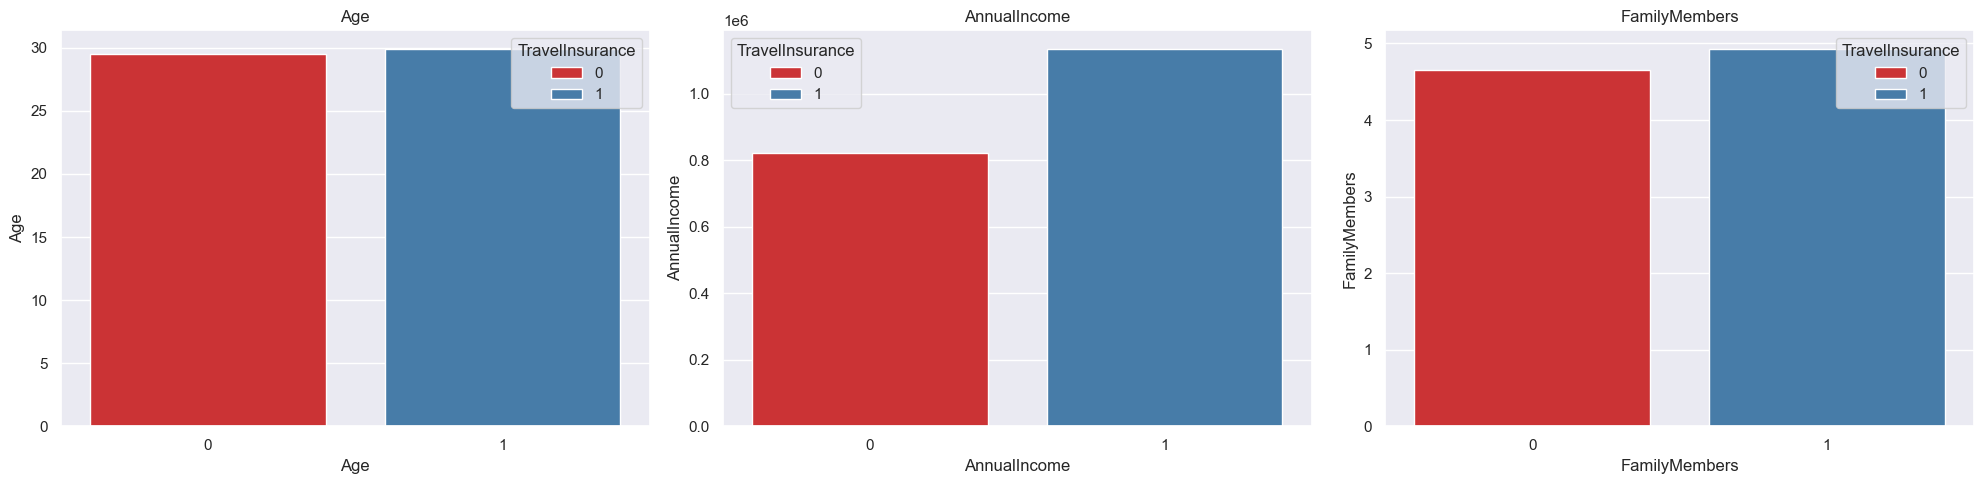

In [12]:
# Numerical Analysis
features = ['Age','AnnualIncome','FamilyMembers']

plt.figure(figsize=(20,5))
sns.set(palette='Set1')
plotnumber = 1

for feature in features:
    ax = plt.subplot(1,3,plotnumber)
    sns.barplot(data=df,x='TravelInsurance',y=feature,hue='TravelInsurance',errorbar=None)
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()

In [13]:
df.groupby('TravelInsurance')[['Age','AnnualIncome','FamilyMembers']].mean()

,Age,AnnualIncome,FamilyMembers
TravelInsurance,,,
0,29.517619,8.212999e+05,4.657009
1,29.888732,1.133239e+06,4.925352


Age
* People who buy and not buy the travel insurance have about the same age average (29.8 years old - 29.5 years old)

Annual Income
* People who buy travel insurance have more income (1133k) than the people who not buy (821k)

Family Member
* People who buy travel insurance have more family members (4.92)than the people who not buy (4.65)

In [14]:
df.columns

Index(['ID', 'Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome',
       'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer',
       'EverTravelledAbroad', 'TravelInsurance'],
      dtype='object')

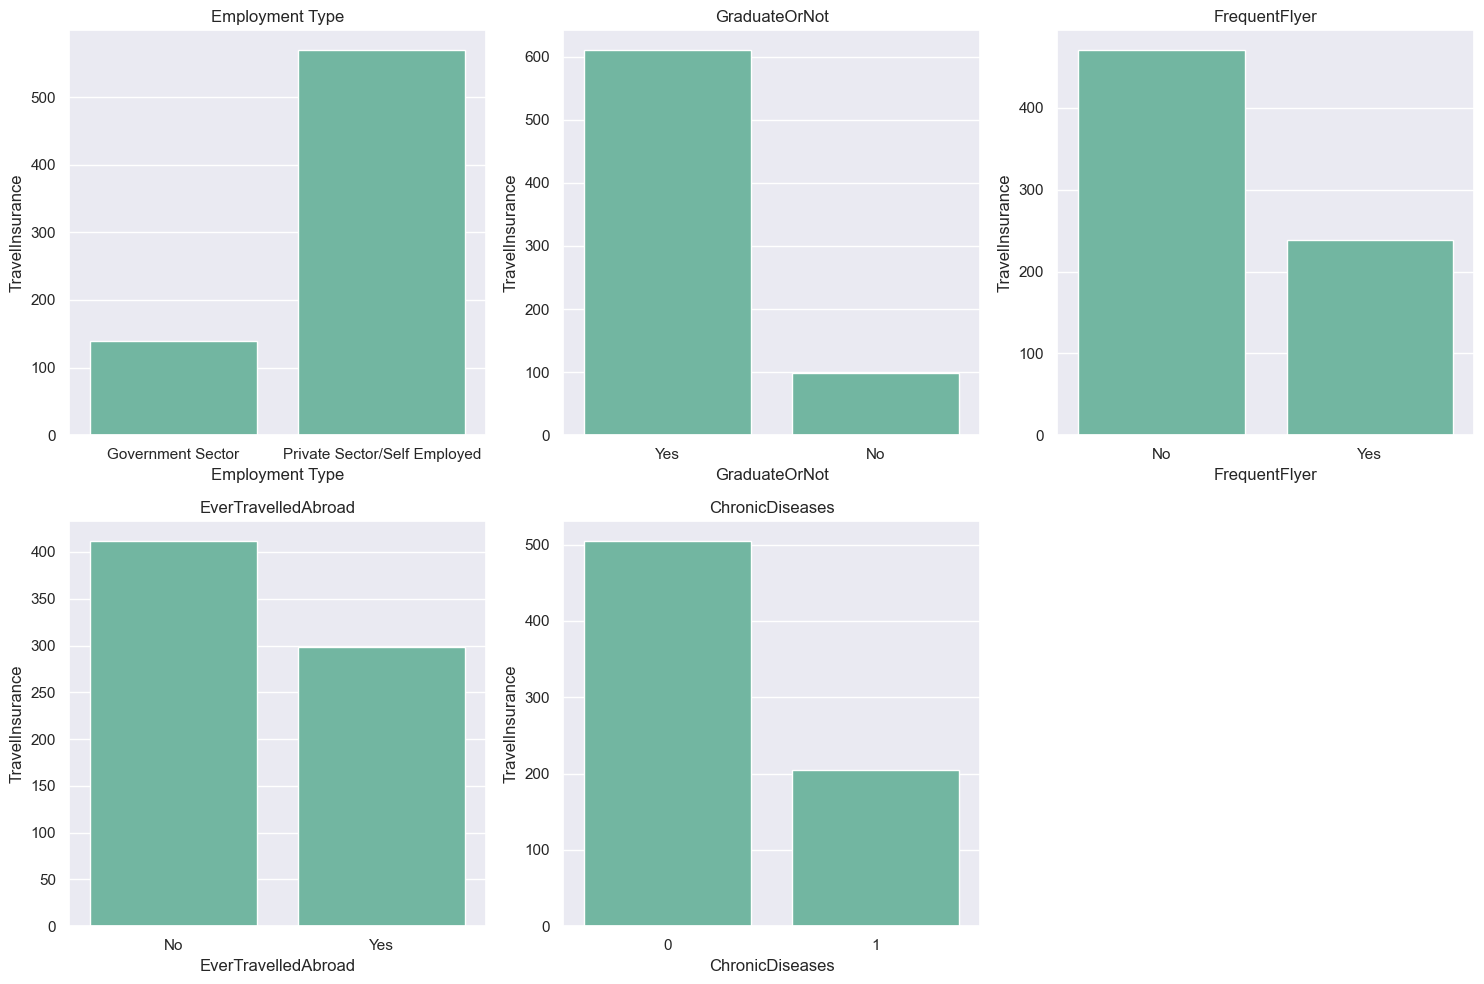

In [15]:
# Categorical Analysis (1)
features = ['Employment Type', 'GraduateOrNot', 'FrequentFlyer','EverTravelledAbroad','ChronicDiseases']

plt.figure(figsize=(15,10))
sns.set(palette='Set2')
plotnumber = 1

for feature in features:
    ax = plt.subplot(2,3,plotnumber)
    sns.barplot(data=df,x=feature,y='TravelInsurance',estimator=np.sum,errorbar=None)
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()

More people who buy travel insurance are in this Category:
* Private Sector / Self Employed
* Graduated (Yes)
* Frequent Flyer (No)
* Ever Travel Abroad (No)
* No ChronicDiseases

In [16]:
def create_pivot(feature):
    df_pivot = df.pivot_table(
        index = 'TravelInsurance',
        columns = feature,
        values = 'ID',
        aggfunc = len
    )
    df_pivot.loc['Total'] = df_pivot.sum()
    df_pivot.loc['%'] = round((df_pivot.loc[1]/df_pivot.loc['Total'])*100,1)

    return df_pivot.T.sort_values('%',ascending=False)



In [17]:
df.columns

Index(['ID', 'Age', 'Employment Type', 'GraduateOrNot', 'AnnualIncome',
       'FamilyMembers', 'ChronicDiseases', 'FrequentFlyer',
       'EverTravelledAbroad', 'TravelInsurance'],
      dtype='object')

In [18]:
create_pivot('GraduateOrNot')

TravelInsurance,0,1,Total,%
GraduateOrNot,,,,
Yes,1081.0,611.0,1692.0,36.1
No,196.0,99.0,295.0,33.6


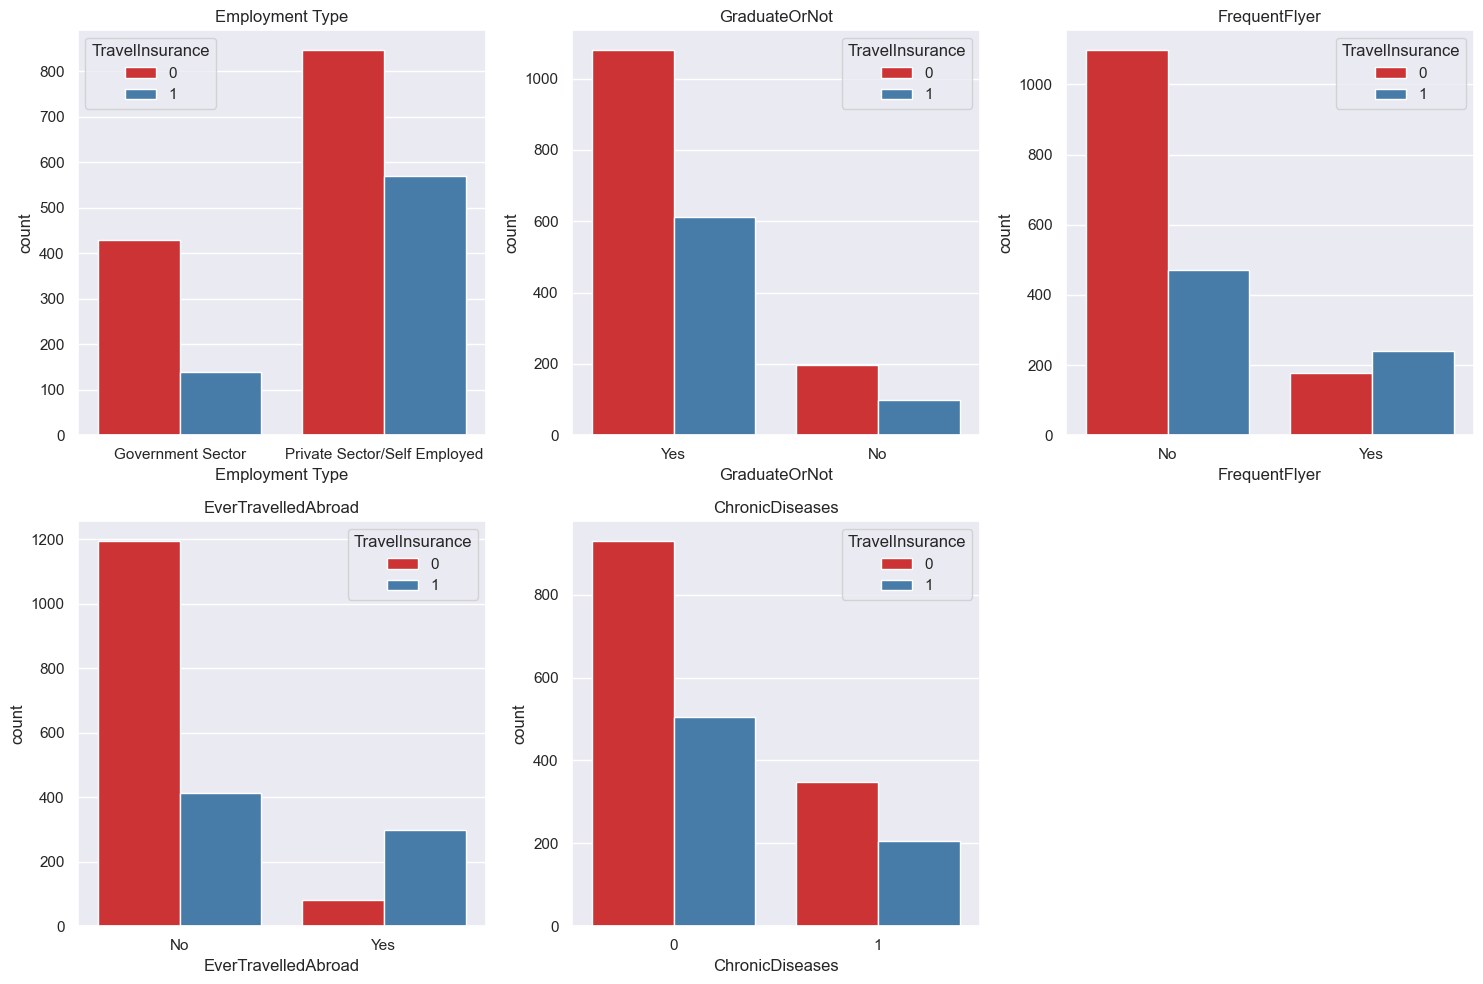

In [19]:
# Categorical Analysis (2)
features = ['Employment Type', 'GraduateOrNot', 'FrequentFlyer','EverTravelledAbroad','ChronicDiseases']

plt.figure(figsize=(15,10))
sns.set(palette='Set1')
plotnumber = 1

for feature in features:
    ax = plt.subplot(2,3,plotnumber)
    # sns.barplot(data=df,x=feature,y='TravelInsurance',estimator=np.sum,errorbar=None)
    sns.countplot(data=df,x=feature,hue='TravelInsurance')
    plt.xlabel(feature)
    plt.title(feature)
    plotnumber+=1
    plt.tight_layout()

Employment Type:
* More people work in Private Sector / Self Employed than in Government Sector, so does the buy and not buy for the travel insurance.

Graduate Or Not:
* raduated People are bigger quantity than those who ungraduated, so does the buy and not buy for tthe travel insurance.

Frequent Flyer:
* More people do not fly frequently, than who regularly fly.
* More people buy travel insurance than who do not buy when they fly frequently.
* More people do buy travel insurance than who buy when they do not fly frequently.

Ever Travel Abroad:
* More people never travel abroad, than who has travel abroad.
* More people buy travel insurance than who do not buy when they have been travel abroad.
* More people do buy travel insurance than who buy when they never travel abroad.

Chronic Disease:
* There are more people who don't have any chronic disease background than it has, so does the buy and not buy for the travel insurance.


# Data Splitting

In [20]:
X = df.drop(columns=['TravelInsurance','ID'])
y = df['TravelInsurance']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.2,
    random_state=0
)

## Data Preprocessing

In [22]:
df.describe(include='object').columns

Index(['Employment Type', 'GraduateOrNot', 'FrequentFlyer',
       'EverTravelledAbroad'],
      dtype='object')

In [25]:
# transformer
transformer = ColumnTransformer([
    ('onehot',OneHotEncoder(),['Employment Type', 'GraduateOrNot', 'FrequentFlyer','EverTravelledAbroad'])]
,remainder='passthrough')

# scaler
scaler = StandardScaler()

In [27]:
# features = list(transformer.get_feature_names_out())

# list_features = []

# for feature in features:
#     list_features.append('_'.join(feature.split('_')[2:]))

# list_features

# BENCHMARK MODEL

In [28]:
logreg = LogisticRegression()
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier(random_state=0)
rf = RandomForestClassifier(random_state=0)
ada = AdaBoostClassifier(tree,random_state=0)
gbc = GradientBoostingClassifier(random_state=0)
xgbc = XGBClassifier(random_state=0,verbosity=0)

In [29]:
# check the best benchmark model on training
models = [logreg,knn,tree,rf,ada,gbc,xgbc]
model_name = []
score = []
train_score = []
std_value = []

for i in models:
    skfold = StratifiedKFold(n_splits=5)
    estimator = Pipeline([
        ('transformer',transformer),
        ('scaler',scaler),
        ('model',i)
    ])

    model_cv = cross_val_score(
        estimator,
        X_train,
        y_train,
        cv=skfold,
        scoring='f1',
        error_score='raise'
    )

    print(i,model_cv)

    score.append(model_cv)
    train_score.append(model_cv.mean())
    std_value.append(model_cv.std())
    model_name.append(i.__class__.__name__)


LogisticRegression() [0.58888889 0.61290323 0.6        0.58638743 0.58695652]
KNeighborsClassifier() [0.66990291 0.62244898 0.70935961 0.64321608 0.63461538]
DecisionTreeClassifier(random_state=0) [0.68122271 0.63849765 0.66981132 0.64788732 0.62857143]
RandomForestClassifier(random_state=0) [0.71232877 0.65714286 0.68269231 0.6635514  0.67326733]
AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=0),
                   random_state=0) [0.73542601 0.66367713 0.6460177  0.64888889 0.64454976]
GradientBoostingClassifier(random_state=0) [0.73958333 0.66666667 0.73015873 0.67379679 0.71657754]
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, l

In [30]:
benchmark_model_train = pd.DataFrame({
    'model':model_name,
    'train_score':train_score,
    'std':std_value}).sort_values(by='train_score',ascending=False)

benchmark_model_train

,model,train_score,std
5,GradientBoostingClassifier,0.705357,0.029683
6,XGBClassifier,0.681284,0.025142
3,RandomForestClassifier,0.677797,0.019321
4,AdaBoostClassifier,0.667712,0.034534
1,KNeighborsClassifier,0.655909,0.030942
2,DecisionTreeClassifier,0.653198,0.019556
0,LogisticRegression,0.595027,0.010215


In [31]:
# check the best benchmark model on test
test_score = []
model_name = []

for i in models:
    model_pipeline = Pipeline([
        ('transformer',transformer),
        ('scaler',scaler),
        ('model',i)
    ])

    # fitting
    model_pipeline.fit(X_train,y_train)

    # predict
    y_pred_test = model_pipeline.predict(X_test)

    # evaluate
    f1 = f1_score(y_test,y_pred_test)
    test_score.append(f1)
    model_name.append(i.__class__.__name__)

In [32]:
benchmark_model_test = pd.DataFrame({
    'model':model_name,
    'test_score':test_score,
    }).sort_values(by='test_score',ascending=False)

benchmark_model_test

,model,test_score
5,GradientBoostingClassifier,0.739130
2,DecisionTreeClassifier,0.696970
3,RandomForestClassifier,0.692308
4,AdaBoostClassifier,0.681818
6,XGBClassifier,0.677419
1,KNeighborsClassifier,0.669323
0,LogisticRegression,0.624473


In [33]:
# combine and compare
benchmark_model = benchmark_model_test.set_index('model').join(benchmark_model_train.set_index('model'))
benchmark_model.drop('std',axis=1,inplace=True)
benchmark_model['diff'] = benchmark_model['test_score'] - benchmark_model['train_score']
benchmark_model['diff'] = benchmark_model['diff'].agg('abs')
benchmark_model.sort_values(by='test_score',ascending=False)

,test_score,train_score,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
AdaBoostClassifier,0.681818,0.667712,0.014106
XGBClassifier,0.677419,0.681284,0.003865
KNeighborsClassifier,0.669323,0.655909,0.013414
LogisticRegression,0.624473,0.595027,0.029445


**Benchmark Model on Score : Gradient Boost**

**Benchmark Model on Stability : Xtreme Gradient Boost**

# Hyperparameter Tuning

### Gradient Boost

In [34]:
# depth of tree
max_depth = list(np.arange(1,10))

# learning rate
learning_rate = list(np.arange(1,100)/100)

# number of tree
n_estimators = list(np.arange(50,500))

# number of train set in each tree
subsample = list(np.arange(2,10)/10)

# number of features used for splitting
max_features = list(np.arange(1,10)/10)

# Hyperparameter GBC
hyperparameter_space_GBC = {
    'model__max_depth':max_depth,
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimators,
    'model__subsample':subsample,
    'model__max_features':max_features,
}


In [35]:
# Stratified K-Fold
skf = StratifiedKFold(n_splits=5)

# Benchmark Model 1
gbc = GradientBoostingClassifier(random_state=0)

# Create algorithm chain
estimator_gbc = Pipeline([
    ('transformer',transformer),
    ('model',gbc)
])

# hyperparameter tuning
random_gbc = RandomizedSearchCV(
    estimator = estimator_gbc,
    param_distributions = hyperparameter_space_GBC,
    cv = skf,
    scoring = 'f1',
    n_jobs = -1,
    n_iter = 20,
    random_state = 0
)

In [36]:
random_gbc.fit(X_train,y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(),
                                                                               ['Employment '
                                                                                'Type',
                                                                                'GraduateOrNot',
                                                                                'FrequentFlyer',
                                                                                'EverTravelledAbroad'])])),
                                             ('model',
                                              GradientBoostingClassifier(random_state=0))]),
                   n_iter=20, n...
                                                                 0.21, 0.22,
                                                                 0.23, 0.24,
                                                                 0.25, 0.26,
                                                                 0.27, 0.28,
                                                                 0.29, 0.3, ...],
                                        'model__max_depth': [1, 2, 3, 4, 5, 6,
                                                             7, 8, 9],
                                        'model__max_features': [0.1, 0.2, 0.3,
                                                                0.4, 0.5, 0.6,
                                                                0.7, 0.8, 0.9],
                                        'model__n_estimators': [50, 51, 52, 53,
                                                                54, 55, 56, 57,
                                                                58, 59, 60, 61,
                                                                62, 63, 64, 65,
                                                                66, 67, 68, 69,
                                                                70, 71, 72, 73,
                                                                74, 75, 76, 77,
                                                                78, 79, ...],
                                        'model__subsample': [0.2, 0.3, 0.4, 0.5,
                                                             0.6, 0.7, 0.8,
                                                             0.9]},
                   random_state=0, scoring='f1')

In [37]:
# pd.DataFrame(random_gbc.cv_results_).sort_values(by='rank_test_score',ascending=True)

In [38]:
print('Gradient Boosting Classifier')
print('Best_Score : ',random_gbc.best_score_)
print('Best_Params : ',random_gbc.best_params_)

Gradient Boosting Classifier
Best_Score :  0.709606567487097
Best_Params :  {'model__subsample': 0.6, 'model__n_estimators': 70, 'model__max_features': 0.6, 'model__max_depth': 3, 'model__learning_rate': 0.02}


### XGBOOST

In [39]:
# depth of tree
max_depth = list(np.arange(1,10))

# learning rate
learning_rate = list(np.arange(1,100)/100)

# number of tree
n_estimators = list(np.arange(50,500))

# number of train set in each tree
subsample = list(np.arange(2,10)/10)

# gamma means the minimum impurity will be decreased
gamma = list(np.arange(1,11))

# number of feature used for each tree
colsample_bytree = list(np.arange(1,10)/10)

# regularization
reg_alpha = list(np.logspace(-3,1,10))

# Hyperparameter XGBC
hyperparameter_space_XGBC = {
    'model__max_depth':max_depth,
    'model__learning_rate':learning_rate,
    'model__n_estimators':n_estimators,
    'model__subsample':subsample,
    'model__gamma':gamma,
    'model__colsample_bytree':colsample_bytree,
    'model__reg_alpha':reg_alpha
}

In [40]:
# benchmark model 2
xgbc = XGBClassifier(random_state=0, verbosity=0)

# create the algorithm chain
estimator_xgbc = Pipeline([
    ('transformer',transformer),
    ('model',xgbc)
])

# hyperparameter tuning
random_xgbc = RandomizedSearchCV(
    estimator = estimator_xgbc,
    param_distributions = hyperparameter_space_XGBC,
    cv = skf,
    scoring = 'f1',
    n_jobs = -1,
    n_iter = 20,
    random_state = 0
)

In [41]:
random_xgbc.fit(X_train,y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
                   estimator=Pipeline(steps=[('transformer',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('onehot',
                                                                               OneHotEncoder(),
                                                                               ['Employment '
                                                                                'Type',
                                                                                'GraduateOrNot',
                                                                                'FrequentFlyer',
                                                                                'EverTravelledAbroad'])])),
                                             ('model',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                                                            callbacks=None...
                                                                54, 55, 56, 57,
                                                                58, 59, 60, 61,
                                                                62, 63, 64, 65,
                                                                66, 67, 68, 69,
                                                                70, 71, 72, 73,
                                                                74, 75, 76, 77,
                                                                78, 79, ...],
                                        'model__reg_alpha': [0.001,
                                                             0.0027825594022071257,
                                                             0.007742636826811269,
                                                             0.021544346900318832,
                                                             0.05994842503189409,
                                                             0.1668100537200059,
                                                             0.46415888336127775,
                                                             1.2915496650148828,
                                                             3.593813663804626,
                                                             10.0],
                                        'model__subsample': [0.2, 0.3, 0.4, 0.5,
                                                             0.6, 0.7, 0.8,
                                                             0.9]},
                   random_state=0, scoring='f1')

In [42]:
print('Xtreme Gradient Boosting Classifier')
print('Best_Score : ',random_xgbc.best_score_)
print('Best_Params : ',random_xgbc.best_params_)

Xtreme Gradient Boosting Classifier
Best_Score :  0.7106993404645976
Best_Params :  {'model__subsample': 0.9, 'model__reg_alpha': 0.05994842503189409, 'model__n_estimators': 167, 'model__max_depth': 2, 'model__learning_rate': 0.84, 'model__gamma': 10, 'model__colsample_bytree': 0.4}


In [43]:
random_xgbc.best_estimator_

Pipeline(steps=[('transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot', OneHotEncoder(),
                                                  ['Employment Type',
                                                   'GraduateOrNot',
                                                   'FrequentFlyer',
                                                   'EverTravelledAbroad'])])),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=0.4, device=None,
                               early_stopping_...
                               feature_types=None, gamma=10, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.84,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=2, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=167, n_jobs=None,
                               num_parallel_tree=None, random_state=0, ...))])

# Model Performance in Test

### Before & After Hyperparameter Tuning : GBC Model

In [44]:
benchmark_model

,test_score,train_score,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
AdaBoostClassifier,0.681818,0.667712,0.014106
XGBClassifier,0.677419,0.681284,0.003865
KNeighborsClassifier,0.669323,0.655909,0.013414
LogisticRegression,0.624473,0.595027,0.029445


In [45]:
# before
model = GradientBoostingClassifier(random_state=0)

model_pipe_gbc = Pipeline([
    ('transformer',transformer),
    ('model',model)
])

model_pipe_gbc.fit(X_train,y_train)

y_pred = model_pipe_gbc.predict(X_test)
f1_score(y_test,y_pred)

0.7391304347826086

In [46]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.99      0.89       256
           1       0.97      0.60      0.74       142

    accuracy                           0.85       398
   macro avg       0.89      0.79      0.82       398
weighted avg       0.87      0.85      0.84       398



In [47]:
# after
gbc_tuning = random_gbc.best_estimator_

y_pred_gbc_tuning = gbc_tuning.predict(X_test)
print(classification_report(y_test,y_pred_gbc_tuning))

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       256
           1       0.94      0.58      0.72       142

    accuracy                           0.84       398
   macro avg       0.87      0.78      0.80       398
weighted avg       0.86      0.84      0.82       398



Text(0.5, 1.0, 'GBC After Tuning')

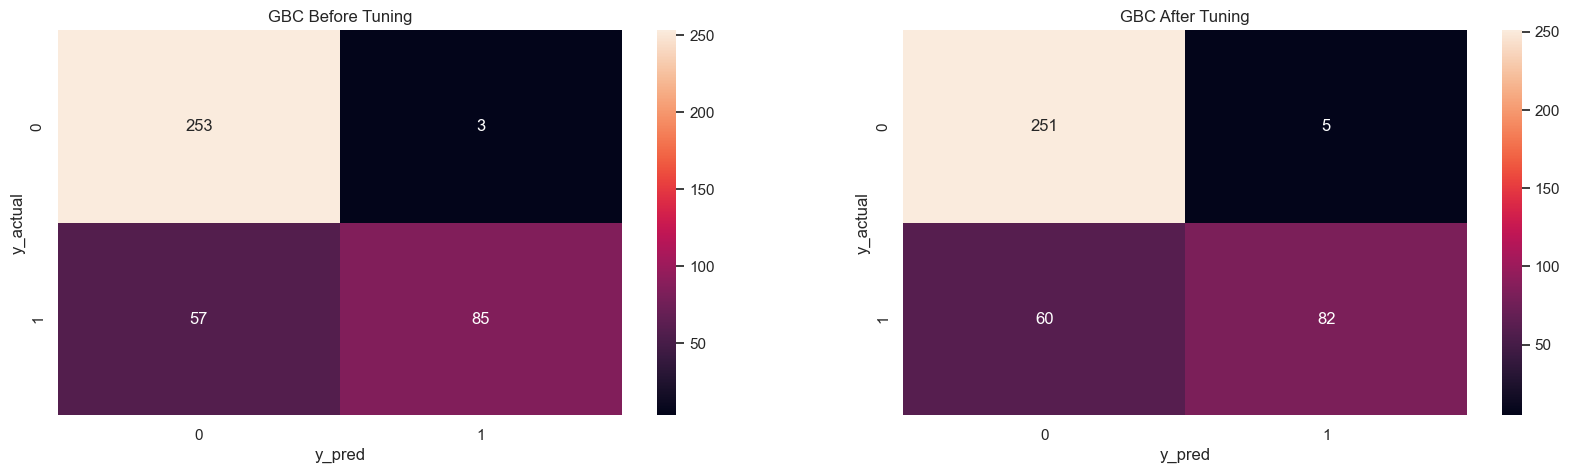

In [48]:
plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('GBC Before Tuning')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test,y_pred_gbc_tuning),annot=True,fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('GBC After Tuning')

**Best Model Score: GBC Before Tuning**

* **TP: 85**
* **TN: 253**
* **FP: 3**
* **FN: 57**

it shows the model are good in minimizing the False Positive, but not really good on minimazing the False Negative.


### Before & After Hyperparameter Tuning : XGBC Model

In [50]:
benchmark_model

,test_score,train_score,diff
model,,,
GradientBoostingClassifier,0.739130,0.705357,0.033774
DecisionTreeClassifier,0.696970,0.653198,0.043772
RandomForestClassifier,0.692308,0.677797,0.014511
AdaBoostClassifier,0.681818,0.667712,0.014106
XGBClassifier,0.677419,0.681284,0.003865
KNeighborsClassifier,0.669323,0.655909,0.013414
LogisticRegression,0.624473,0.595027,0.029445


In [49]:
# before
model = XGBClassifier(random_state=0,verbosity=0)

model_pipe_xgbc = Pipeline([
    ('transformer',transformer),
    ('model',model)
])

model_pipe_xgbc.fit(X_train,y_train)

y_pred = model_pipe_xgbc.predict(X_test)
f1_score(y_test,y_pred)

0.6774193548387096

In [52]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.91      0.85       256
           1       0.79      0.59      0.68       142

    accuracy                           0.80       398
   macro avg       0.80      0.75      0.77       398
weighted avg       0.80      0.80      0.79       398



In [51]:
# after
xgbc_tuning = random_xgbc.best_estimator_

y_pred_xgbc_tuning = xgbc_tuning.predict(X_test)
print(classification_report(y_test,y_pred_xgbc_tuning))

              precision    recall  f1-score   support

           0       0.81      0.98      0.89       256
           1       0.93      0.60      0.73       142

    accuracy                           0.84       398
   macro avg       0.87      0.79      0.81       398
weighted avg       0.86      0.84      0.83       398



In [53]:
f1_score(y_test,y_pred_xgbc_tuning)

0.7296137339055794

Text(0.5, 1.0, 'XGBC After Tuning')

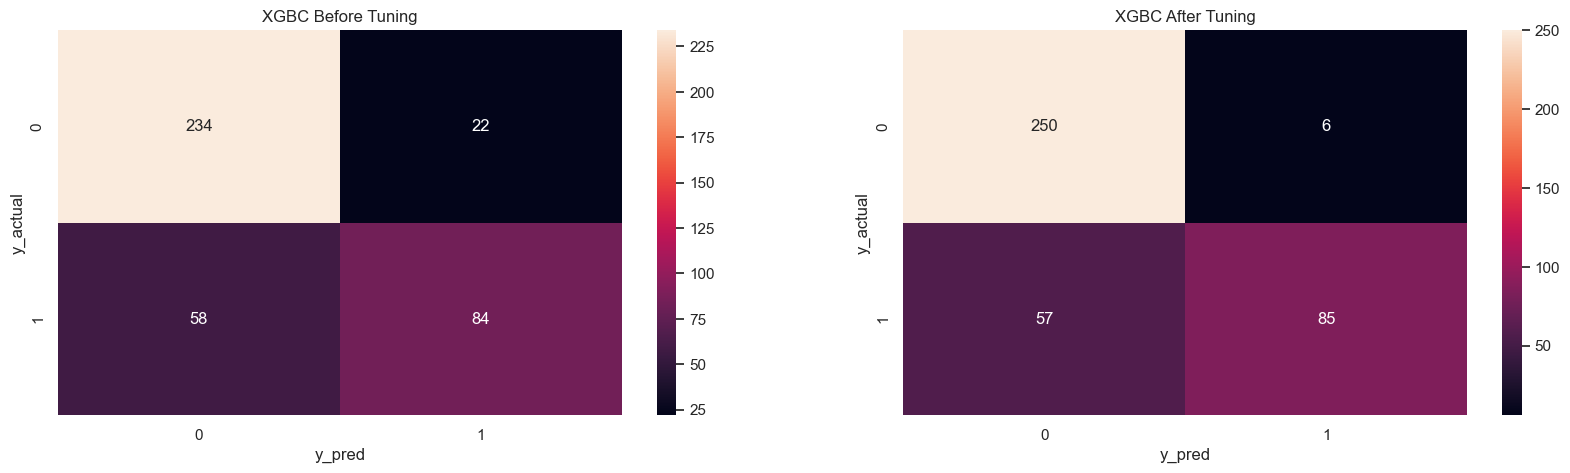

In [54]:
plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('XGBC Before Tuning')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test,y_pred_xgbc_tuning),annot=True,fmt='.0f')
plt.xlabel('y_pred')
plt.ylabel('y_actual')
plt.title('XGBC After Tuning')

**Best model remain 'Gradient Boosting before Hyperparameter Tuning'. XGBoost Tuning only hit 0.7296 F1_score.**

# Adjusting Threshold

In [60]:
# predict probabilities

# model_threshold = model_pipe_gbc
# model_threshold = gbc_tuning
model_threshold = xgbc_tuning

y_hat = model_threshold.predict_proba(X_test)

# ---------------------------------------------

th_value = [i/100 for i in range(20,80)]
score_list = []
score = 0

for i in th_value:

    # predict
    y_prob = model_threshold.predict_proba(X_test)[:,1]
    y_pred = np.where(y_prob>i,1,0)

    score_temp = f1_score(y_test,y_pred)
    score_list.append(score_temp)

    if score_temp > score:
        score = score_temp

        best_score = score
        best_th = i

print('Best F1 Score :',best_score)
print('Best Threshold :',best_th)

Best F1 Score : 0.7359307359307359
Best Threshold : 0.54


**after adjusting threshold, the best model still in GBC before tuning, with best threshold in 0.49**

# **FINAL MODEL**

In [61]:
# Best Model
model_final = model_pipe_gbc

# Predict
y_prob = model_final.predict_proba(X_test)
y_pred = np.where(y_prob>0.49,1,0)

### Feature Importance

In [75]:
# model_final['model'] same with model_final[1] same with model_final[-1]
# but for consistency (whether you got more than 1 preprocessing), use model_final[-1] to get the model

GradientBoostingClassifier(random_state=0)

In [72]:
features = list(transformer.get_feature_names_out())

list_features = []

for feature in features:
    list_features.append('_'.join(feature.split('_')[2:]))

list_features

['Employment Type_Government Sector',
 'Employment Type_Private Sector/Self Employed',
 'GraduateOrNot_No',
 'GraduateOrNot_Yes',
 'FrequentFlyer_No',
 'FrequentFlyer_Yes',
 'EverTravelledAbroad_No',
 'EverTravelledAbroad_Yes',
 'Age',
 'AnnualIncome',
 'FamilyMembers',
 'ChronicDiseases']

In [77]:
# assign feature importance to variable
imp = model_final[-1].feature_importances_
imp

array([0.0040731 , 0.00334192, 0.00472164, 0.00719067, 0.0043529 ,
       0.00634636, 0.00155276, 0.00235692, 0.10566222, 0.63575807,
       0.20453002, 0.02011344])

In [79]:
# to dataframe
feature_imp = pd.DataFrame({
    'Importance':imp,
    'Feature':list_features
}).sort_values(by='Importance',ascending=False)
feature_imp

,Importance,Feature
9,0.635758,AnnualIncome
10,0.204530,FamilyMembers
8,0.105662,Age
11,0.020113,ChronicDiseases
3,0.007191,GraduateOrNot_Yes
5,0.006346,FrequentFlyer_Yes
2,0.004722,GraduateOrNot_No
4,0.004353,FrequentFlyer_No
0,0.004073,Employment Type_Government Sector
1,0.003342,Employment Type_Private Sector/Self Employed


<Axes: xlabel='Importance', ylabel='Feature'>

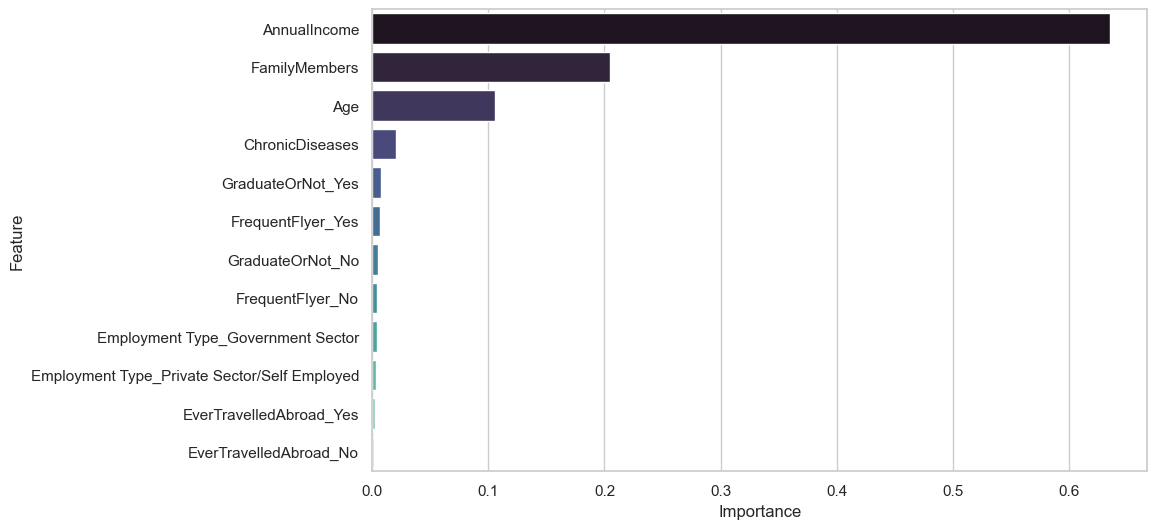

In [80]:
# visualization
plt.figure(figsize=(10,6))
sns.set_theme(style='whitegrid')
sns.barplot(data=feature_imp,x='Importance',y='Feature',orient='h',palette='mako')

# Save The Model

In [81]:
import pickle

model_final = model_pipe_gbc
model_final.fit(X_train,y_train)

pickle.dump(model_final, open('models/Day_50_Model_Travel_GBC.sav','wb'))

# **EXPLAINABLE AI**

In [82]:
import shap

In [83]:
model_final[1].predict

<bound method GradientBoostingClassifier.predict of GradientBoostingClassifier(random_state=0)>

In [84]:
# explainer
explainer = shap.Explainer(
    model_final[1].predict,
    model_final[0].transform(X_test)
)

shap_values = explainer(model_final[0].transform(X_test))

PermutationExplainer explainer: 399it [00:38,  9.03it/s]                         


In [95]:
i = 10
X_test.iloc[i],y_test.iloc[i]

(Age                                   33
 Employment Type        Government Sector
 GraduateOrNot                        Yes
 AnnualIncome                      700000
 FamilyMembers                          3
 ChronicDiseases                        0
 FrequentFlyer                         No
 EverTravelledAbroad                   No
 Name: 1205, dtype: object,
 0)

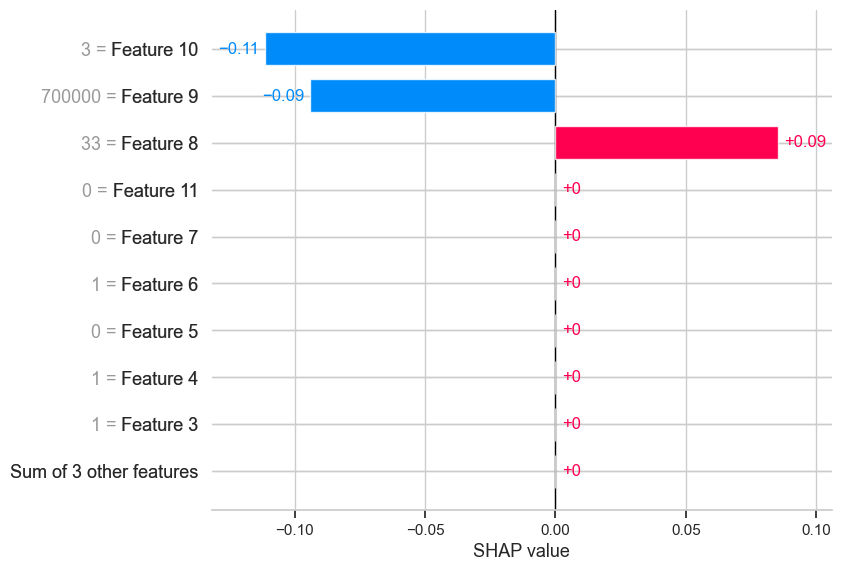

In [96]:
# shap_values for explain obvervation in test
shap.plots.bar(shap_values[i])

In [94]:
[i for i in enumerate(list_features)]

[(0, 'Employment Type_Government Sector'),
 (1, 'Employment Type_Private Sector/Self Employed'),
 (2, 'GraduateOrNot_No'),
 (3, 'GraduateOrNot_Yes'),
 (4, 'FrequentFlyer_No'),
 (5, 'FrequentFlyer_Yes'),
 (6, 'EverTravelledAbroad_No'),
 (7, 'EverTravelledAbroad_Yes'),
 (8, 'Age'),
 (9, 'AnnualIncome'),
 (10, 'FamilyMembers'),
 (11, 'ChronicDiseases')]

In [98]:
# shap_values for explain all features in train
X_train_trans = model_final[0].transform(X_train)

# explainer
explainer = shap.TreeExplainer(
    model_final.named_steps['model'],
    data = X_train_trans,
    feature_perturbation = 'interventional',
    model_output = 'probability'
)

# shap values
shap_values = explainer.shap_values(X_train_trans)

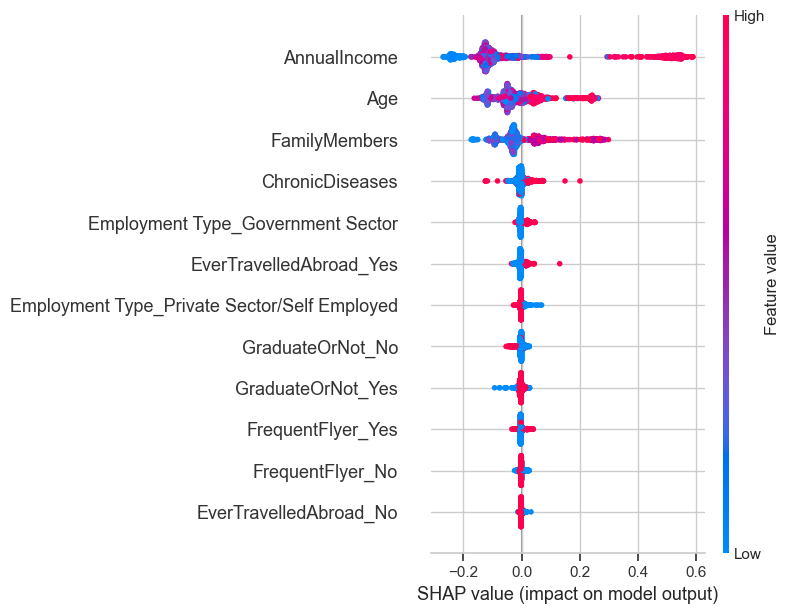

In [100]:
# summary plot for model in train
shap.summary_plot(
    shap_values,
    X_train_trans,
    feature_names=list_features
)

In [101]:
# shap js
def shap_plot(idx, model, dataset):
    explainerModel = shap.TreeExplainer(model)
    shap_values_model = explainerModel.shap_values(dataset)
    p = shap.force_plot(explainerModel.expected_value, shap_values_model[idx], dataset.iloc[[idx]])
    return (p)

In [103]:
X_test.iloc[0],y_test.iloc[0]

(Age                                              25
 Employment Type        Private Sector/Self Employed
 GraduateOrNot                                   Yes
 AnnualIncome                                1400000
 FamilyMembers                                     5
 ChronicDiseases                                   0
 FrequentFlyer                                    No
 EverTravelledAbroad                             Yes
 Name: 1926, dtype: object,
 1)

In [105]:
X_test_preprocessed = pd.DataFrame(model_final[0].transform(X_test))
X_test_preprocessed.columns = list_features
X_test_preprocessed

,Employment Type_Government Sector,Employment Type_Private Sector/Self Employed,GraduateOrNot_No,GraduateOrNot_Yes,FrequentFlyer_No,FrequentFlyer_Yes,EverTravelledAbroad_No,EverTravelledAbroad_Yes,Age,AnnualIncome,FamilyMembers,ChronicDiseases
0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,25.0,1400000.0,5.0,0.0
1,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,26.0,500000.0,9.0,0.0
2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,34.0,1500000.0,6.0,1.0
3,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,25.0,1150000.0,4.0,0.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,31.0,1400000.0,6.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
393,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,34.0,700000.0,6.0,0.0
394,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,34.0,1500000.0,4.0,0.0
395,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,34.0,700000.0,4.0,0.0
396,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,34.0,1300000.0,5.0,0.0


In [107]:
shap.initjs()

In [110]:
# let's compare the real result
i = 100

print(f'The prediction of this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do Not Buy')} --> from y_test')

shap_plot(
    i,
    model_final['model'],
    X_test_preprocessed
)

The prediction of this customer is : Do Not Buy --> from y_test


In [111]:
# LIME
import lime
from lime import lime_tabular


In [117]:
# explainer
explainer = lime_tabular.LimeTabularExplainer(
    training_data = model_final[0].transform(X_train),
    feature_names = list_features,
    class_names = ['Not Buy','Buy'],
    mode = 'classification'
)

explainer

The prediction of this customer is : Buy --> from y_test


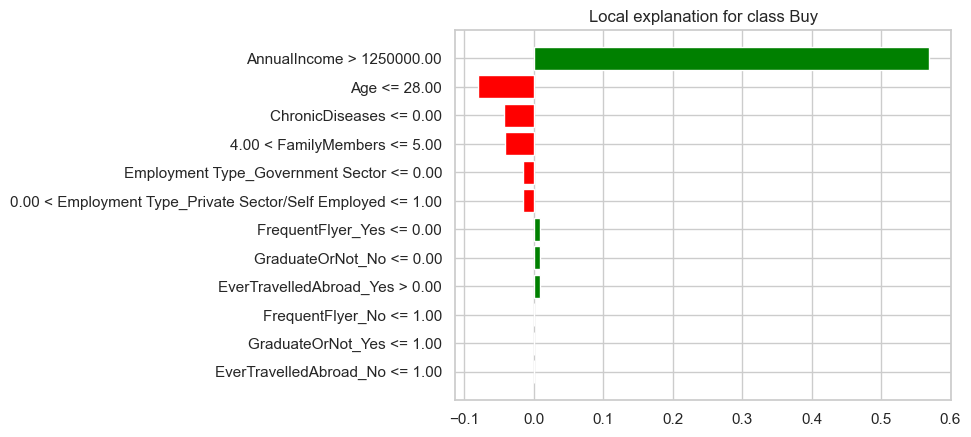

In [118]:
# lime observation using pyplot figure
i = 0

print(f'The prediction of this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do Not Buy')} --> from y_test')

exp = explainer.explain_instance(
    X_test_preprocessed.iloc[i],
    model_final['model'].predict_proba,
    num_features=12
)

exp.as_pyplot_figure()
plt.show()


In [120]:
# lime observation using pyplot figure
i = 1

print(f'The prediction of this customer is : {('Buy' if y_test.iloc[i] == 1 else 'Do Not Buy')} --> from y_test')

exp = explainer.explain_instance(
    X_test_preprocessed.iloc[i],
    model_final['model'].predict_proba,
)

exp.show_in_notebook(show_table=True)


The prediction of this customer is : Do Not Buy --> from y_test
